<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Task%202P%20SIG731%20BM_V3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wind and Temperature at the New York City Airports in 2013: A pandas-Based Analysis

**Author:** Bylhah Mugotitsa<br>
**Student number:** s22648262<br>
**Email:** s22648262@deakin.edu.au<br>
**Unit:** SIG731, Trimester 3 2026, Task 2P

## Introduction

Wind affects runway choice, aircraft separation and delays, so airports record the
weather every hour. This report studies the hourly weather observations made in 2013
at the three airports that serve New York City: Newark Liberty (EWR),
John F. Kennedy (JFK) and LaGuardia (LGA). The data come from the *nycflights13*
collection [1] and are processed with *pandas* [2] and *NumPy* [3], with
*Matplotlib* [4] used for the graphics.

I first convert the measurements from imperial to metric units. I then describe how
windy each day was at LGA, plot the daily values and identify the ten windiest days.
Next, I find and remove an impossible wind speed reading, after which I compare the
monthly mean wind speeds of the three airports. Finally, I examine the missing
temperature readings at JFK and test how much linear interpolation changes the daily
averages.

## 1. Setting Up the Environment and Loading the Data

I begin by importing every package and loading the data once. My steps are as follows:

1. I imported `numpy` for the missing value marker `np.nan`, `pandas` for the data
   frame, and `matplotlib` for the plots.
2. I Load the file `nycflights13_weather.csv.gz` file.
3. I read the file with `pd.read_csv`. I set `comment="#"` because the file opens with
   a block of documentation lines that start with `#`. I did not unzip the file, as
   *pandas* recognises the `.gz` extension and decompresses it automatically.

In [1]:
import os
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_file = "nycflights13_weather.csv.gz"

# Ask for the file only in an online session where it is not present
if "google.colab" in sys.modules and not os.path.exists(data_file):
    from google.colab import files
    files.upload()

weather = pd.read_csv(data_file, comment="#")

print(f"Rows: {weather.shape[0]}, columns: {weather.shape[1]}")
print(weather[["origin", "hour", "time_hour"]].head(1))

Saving nycflights13_weather.csv.gz to nycflights13_weather.csv.gz
Rows: 26130, columns: 15
  origin  hour            time_hour
0    EWR     0  2013-01-01 01:00:00


The data frame holds 26,130 hourly records and 15 columns. A complete year at three
airports would give 3 x 365 x 24 = 26,280 records, so 150 are absent. I examine
those of JFK in Section 7.

The `time_hour` column needs care, because it is one hour ahead of the `year`, `month`,
`day` and `hour` fields. The first record above shows this: its hour is 0, yet
`time_hour` states 01:00. I therefore rebuilt the column from the four reliable fields
using `pd.to_datetime`. I also created a `date` column with `dt.normalize()`, which sets
the time to midnight, so that all hours of one day share one label.

In [2]:
fields = ["year", "month", "day", "hour"]
weather["time_hour"] = pd.to_datetime(weather[fields])
weather["date"] = weather["time_hour"].dt.normalize()

print("First record:", weather["time_hour"].min())
print("Last record: ", weather["time_hour"].max())

First record: 2013-01-01 00:00:00
Last record:  2013-12-30 23:00:00


The corrected timestamps run from midnight on 1 January to 23:00 on 30 December 2013.
There are no records for 31 December, so 364 days are available rather than 365.

## 2. Converting the Measurements to Metric Units

The original values are in imperial units. I converted them with the factors below and
wrote the results back to the same columns, so the old values were overwritten.

| Columns | From | To | Conversion |
|:---|:---|:---|:---|
| `temp`, `dewp` | degrees Fahrenheit | degrees Celsius | $(x - 32) \times 5/9$ |
| `precip` | inches | millimetres | $x \times 25.4$ |
| `visib` | miles | metres | $x \times 1609.344$ |
| `wind_speed`, `wind_gust` | miles per hour | metres per second | $x \times 0.44704$ |

I selected columns that share a formula together, for example
`weather[["temp", "dewp"]]`, because *pandas* applies arithmetic to every value at
once and no loop is needed. I left `pressure` unchanged, as one millibar equals one
hectopascal, a metric unit. I also left humidity (a percentage) and wind direction
(in degrees) unchanged. Since this cell overwrites its own input, it must be run only
once after loading the data.

In [3]:
temp_cols = ["temp", "dewp"]
wind_cols = ["wind_speed", "wind_gust"]

weather[temp_cols] = (weather[temp_cols] - 32) * 5 / 9
weather["precip"] = weather["precip"] * 25.4
weather["visib"] = weather["visib"] * 1609.344
weather[wind_cols] = weather[wind_cols] * 0.44704

converted = temp_cols + ["precip", "visib"] + wind_cols
weather[converted].agg(["min", "mean", "max"]).round(2)

,temp,dewp,precip,visib,wind_speed,wind_gust
min,-11.70,-23.30,0.00,0.00,0.00,0.00
mean,12.89,5.21,0.07,14813.73,4.65,5.35
max,37.80,25.60,29.97,16093.44,468.66,539.32


The converted values are mostly sensible. Temperature ranges from -11.7 to 37.8 degrees
Celsius, which suits New York winters and summers. Visibility never exceeds
16,093.44 metres, which is exactly 10 miles, so the instruments appear to report
10 miles as an upper limit.

One value stands out. The maximum wind speed is 468.66 metres per second, which is
faster than the speed of sound (about 340 metres per second) and is highly not correct.

## 3. Daily Mean Wind Speeds at LGA

Hourly wind speeds vary a great deal, so I summarised them by day. My steps were:

1. I kept only the LGA rows with the Boolean condition `weather["origin"] == "LGA"`.
2. I grouped these rows by `date` with `groupby`, which places all the hours of a day
   in one group. This is equivalent to grouping by year, month and day together.
3. I took the mean of `wind_speed` in each group. By default, `mean` skips missing
   values.

In [4]:
lga = weather.loc[weather["origin"] == "LGA"]
lga_daily = lga.groupby("date")[["wind_speed"]].mean()

print(f"Number of daily means: {len(lga_daily)}")
lga_daily.round(2)

Number of daily means: 364


,wind_speed
date,
2013-01-01,6.69
2013-01-02,6.43
2013-01-03,4.91
2013-01-04,6.88
2013-01-05,5.14
...,...
2013-12-26,3.30
2013-12-27,5.40
2013-12-28,4.67


I obtained 364 daily means, one for each day from 1 January to 30 December. The table
shows the first and last five of them. A few means rest on fewer than 24 hourly readings
because some records are absent; for example, 26 October and 3 November have only
19 each.

I then plotted all the daily means as one line. I used dates on the x-axis and asked
`MonthLocator` to place one tick at the start of each month and `DateFormatter("%b")`
to print the abbreviated month name. I also added a dashed line for the average of the
daily means, which makes windy and calm days easy to tell apart.

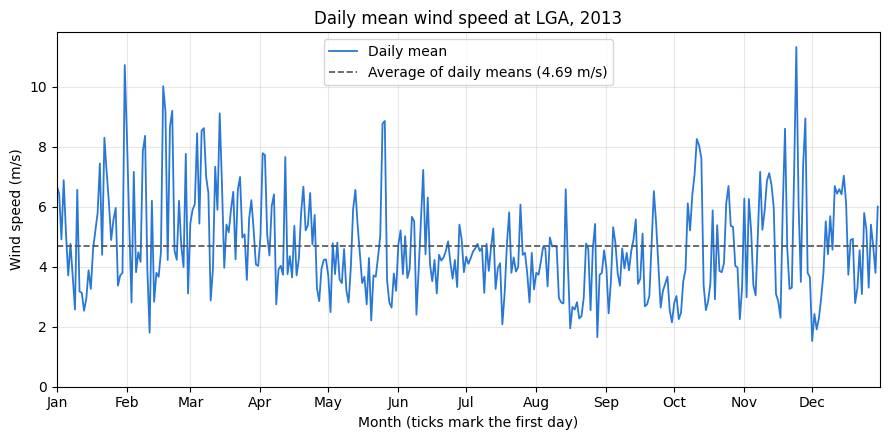

In [5]:
lga_mean = lga_daily["wind_speed"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(lga_daily.index, lga_daily["wind_speed"],
        color="#2a78d6", linewidth=1.3, label="Daily mean")
ax.axhline(lga_mean, color="#52514e", linestyle="--", linewidth=1.2,
           label=f"Average of daily means ({lga_mean:.2f} m/s)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(pd.Timestamp("2013-01-01"), pd.Timestamp("2013-12-31"))
ax.set_ylim(bottom=0)
ax.set_title("Daily mean wind speed at LGA, 2013")
ax.set_xlabel("Month (ticks mark the first day)")
ax.set_ylabel("Wind speed (m/s)")
ax.grid(alpha=0.3)
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

The average of the daily means is 4.69 metres per second. The line moves up and down
sharply from one day to the next, so a windy day can be followed by a much calmer one.
A seasonal pattern is also visible. The tallest peaks occur in late January, February,
March and November, whereas the values from July to September are lower and less
variable. The calmest day was 1 December (1.52 metres per second), only one week after
the windiest day of the year, which shows how quickly conditions can change.

## 4. The Ten Windiest Days at LGA

To find the windiest days, I applied `nlargest(10, "wind_speed")` to the daily means.
This function selects the ten rows with the greatest values and returns them in
descending order, so no separate sorting step is required. I rounded the result to 2 decimals.

In [6]:
windiest = lga_daily.nlargest(10, "wind_speed")
windiest.round(2)

,wind_speed
date,
2013-11-24,11.32
2013-01-31,10.72
2013-02-17,10.01
2013-02-21,9.19
2013-02-18,9.17
2013-03-14,9.11
2013-11-28,8.94
2013-05-26,8.85
2013-05-25,8.77


The windiest day was 24 November 2013, with a mean of 11.32 metres per second, which is
about 2.4 times the yearly average. It is followed by 31 January (10.72) and
17 February (10.01), the only other days above 10 metres per second.

Four of the ten days fall in February, and 17, 18, 20 and 21 February lie within a
single five-day period. The neighbouring dates of 25 and 26 May also appear. This
clustering suggests that strong winds at LGA can persist for several days. No day from
June to October enters the list, which agrees with the plot above.

## 5. Locating and Removing the Wind Speed Outlier

Before comparing the airports, I had to correct the impossible wind speed noticed in
Section 2. I located it from the data rather than typing in its date or row number:

1. I used `idxmax()` to obtain the row label of the greatest wind speed.
2. I used `nlargest(2)` to compare this value with the second greatest. A genuine
   extreme would be close to its neighbour, while a recording error would stand alone.
3. I replaced the value with `np.nan` using `.loc[row, column]`, so that the record is
   kept, but the mean ignores the faulty reading.

In [7]:
top_two = weather["wind_speed"].nlargest(2)
outlier_row = weather["wind_speed"].idxmax()
outlier = weather.loc[outlier_row, ["origin", "time_hour", "wind_speed"]]

# Replace the faulty reading with a missing value
weather.loc[outlier_row, "wind_speed"] = np.nan

print(f"Outlier: {outlier['wind_speed']:.2f} m/s at "
      f"{outlier['origin']}, {outlier['time_hour']}")
print(f"Next greatest reading: {top_two.iloc[1]:.2f} m/s")
print(f"Ratio of the two: {top_two.iloc[0] / top_two.iloc[1]:.1f}")
print(f"Maximum after replacement: {weather['wind_speed'].max():.2f} m/s")

Outlier: 468.66 m/s at EWR, 2013-02-12 08:00:00
Next greatest reading: 19.03 m/s
Ratio of the two: 24.6
Maximum after replacement: 19.03 m/s


The outlier was recorded at EWR at 08:00 on 12 February 2013. Its value of 468.66 metres
per second is almost 25 times greater than the next highest reading of 19.03. It is also
more than four times the verified world record gust outside a tornado, about 113 metres
per second [5], so it must be an error. After the replacement, the maximum is
19.03 metres per second, which is plausible.

 The `wind_gust` value in the same row looks faulty, because every gust in this
file is a fixed multiple of the wind speed (about 1.15). I do not use the gust column
in the analysis, so I left it as it was.

## 6. Monthly Mean Wind Speeds at the Three Airports

With the outlier removed, I compared the airports by month. I grouped the rows by
`month` and `origin` at the same time, which gives one mean for each of the
12 x 3 = 36 combinations. I then called `unstack()`, which moves the airport codes from
the rows to the columns, so each airport has its own column and the table is ready for
plotting. Finally, I replaced the month numbers with month names.

In [8]:
monthly = (
    weather.groupby(["month", "origin"])["wind_speed"].mean().unstack()
)
month_start = pd.to_datetime(monthly.index.astype(str), format="%m")
monthly.index = pd.Index(month_start.strftime("%b"), name="month")

monthly.round(2)

origin,EWR,JFK,LGA
month,,,
Jan,4.33,5.38,5.07
Feb,4.73,5.95,5.52
Mar,5.14,6.21,5.85
Apr,4.27,5.58,4.93
May,3.71,4.60,4.20
Jun,4.20,4.88,4.46
Jul,4.02,4.50,4.18
Aug,3.35,4.31,3.73
Sep,3.57,4.36,3.93


All 36 means lie between 3.35 metres per second (EWR in August) and 6.21 metres per
second (JFK in March). Removing the outlier mattered: with it, the February mean of EWR
would have been 5.43 instead of 4.73 metres per second. A single wrong reading among
several hundred would have raised that mean by about 15 per cent and made February,
rather than March, appear to be the windiest month at EWR.


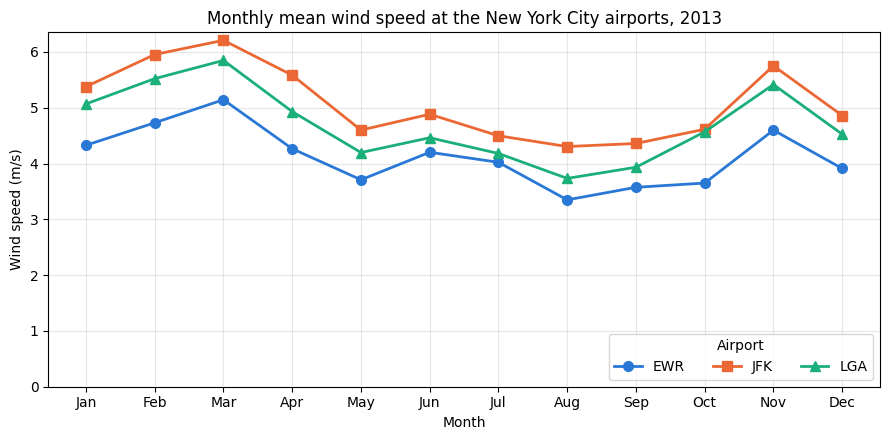

In [9]:
styles = {
    "EWR": ("#2a78d6", "o"),
    "JFK": ("#eb6834", "s"),
    "LGA": ("#1baf7a", "^"),
}

fig, ax = plt.subplots(figsize=(9, 4.5))
for airport, (colour, marker) in styles.items():
    ax.plot(monthly.index, monthly[airport], color=colour,
            marker=marker, markersize=7, linewidth=2, label=airport)
ax.set_title("Monthly mean wind speed at the New York City airports, 2013")
ax.set_xlabel("Month")
ax.set_ylabel("Wind speed (m/s)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(title="Airport", loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

The three curves have almost the same shape and never cross. JFK was the windiest
airport in all twelve months, LGA was second and EWR was the calmest. A likely reason is
location: JFK lies close to the Atlantic coast, while EWR lies further inland.

March was the windiest month at all three airports and August was the calmest. The
curves rise from January to March, fall in April and May, rise again in June, decline
until August, and climb to a second peak in November. The matching shapes suggest that
regional weather drives the monthly pattern, while the local setting determines how
windy each airport is.

## 7. Missing Temperature Readings at JFK

So far I have relied on the records that are present. I now examine the gaps, using the
JFK temperatures. A reading can be missing in two ways: the row exists but its
temperature is `NaN`, or the whole row is absent. To capture both cases, I did the
following:

1. I built a complete list of the 8,760 hours of 2013 with `pd.date_range`.
2. I set `time_hour` as the index of the JFK rows and called `reindex` with that list.
   Absent hours became new rows filled with `NaN`.
3. I selected the rows in which `temp` is missing. I also counted the two types
   separately.
4. I grouped the missing hours by date, so that the list is short enough to read.

In [10]:
all_hours = pd.date_range("2013-01-01 00:00", "2013-12-31 23:00",
                          freq="h", name="time_hour")
jfk = weather.loc[weather["origin"] == "JFK"].set_index("time_hour")
jfk_full = jfk.reindex(all_hours)

missing = all_hours[jfk_full["temp"].isna()]
omitted = all_hours.difference(jfk.index)

print(f"Marked as missing: {jfk['temp'].isna().sum()}")
print(f"Records omitted:   {len(omitted)}")
print(f"Total missing:     {len(missing)}\n")

hours = pd.Series(missing.strftime("%H"), index=missing.date)
hours_by_day = hours.groupby(level=0).agg(" ".join)
print("Date        Missing hours")
for day, text in hours_by_day.items():
    print(f"{day}  {text}")

Marked as missing: 0
Records omitted:   49
Total missing:     49

Date        Missing hours
2013-01-01  05
2013-02-21  05
2013-03-05  06
2013-03-31  01
2013-04-03  00
2013-08-13  04
2013-08-16  04
2013-08-19  21
2013-08-22  22
2013-08-23  00 01
2013-10-26  00 01 02 03 04
2013-10-27  01
2013-11-01  07 08
2013-11-03  00 01 02 03 04
2013-11-04  15
2013-12-31  00 01 02 03 04 05 06 07 08 09 10 11 12 13 14 15 16 17 18 19 20 21 22 23


JFK has 49 missing temperatures. None is marked explicitly, so all 49 belong to records
that were omitted altogether, and a check with `isna()` on the original data would have
found none of them. They fall on 16 dates: 25 are spread over 15 dates, and the other
24 make up the whole of 31 December. Apart from that day, the longest gaps occur on
26 October and 3 November, with five hours each.

These hours follow the corrected timestamps. In the original, shifted `time_hour`
column, each would appear one hour later. For example, the gap at 05:00 on 21 February
would be labelled 06:00.

I then added the omitted records to the main data. I created a small data frame that
holds only the airport code and the date-time fields, and appended it to `weather` with
`pd.concat`. Columns that the small frame does not contain are filled with `NaN`
automatically.

In [11]:
new_rows = pd.DataFrame({"origin": "JFK", "time_hour": omitted})
new_rows["date"] = new_rows["time_hour"].dt.normalize()
for field in fields:
    new_rows[field] = getattr(new_rows["time_hour"].dt, field)

weather = pd.concat([weather, new_rows], ignore_index=True)
weather = weather.sort_values(["origin", "time_hour"], ignore_index=True)

n_jfk = (weather["origin"] == "JFK").sum()
print(f"Records added: {len(new_rows)}")
print(f"JFK records now available: {n_jfk}")

Records added: 49
JFK records now available: 8760


JFK now has 8,760 records, one for each hour of the year (365 x 24), and the new rows
contain no measurements. Next, I computed the daily mean temperatures in two ways:

* **Missing values omitted:** I averaged only the readings that exist.
* **Linearly interpolated:** I first filled each gap along a straight line between the
  reading before it and the reading after it, and then averaged. I set
  `limit_area="inside"` so that only gaps with readings on both sides are filled. The
  gap on 31 December has no later reading, hence any value there would be a guess.

In [12]:
jfk_temp = weather.loc[weather["origin"] == "JFK"]
jfk_temp = jfk_temp.set_index("time_hour")["temp"]
filled = jfk_temp.interpolate(method="linear", limit_area="inside")

daily_temp = pd.DataFrame({
    "omitted": jfk_temp.resample("D").mean(),
    "interpolated": filled.resample("D").mean(),
}).rename_axis("date")
daily_temp["difference"] = (
    daily_temp["interpolated"] - daily_temp["omitted"]
)
changed = daily_temp.loc[daily_temp["difference"].abs() > 1e-9]

print(f"Hours filled: {jfk_temp.isna().sum() - filled.isna().sum()}")
print(f"Days with a changed mean: {len(changed)}")
changed.round(2)

Hours filled: 25
Days with a changed mean: 15


,omitted,interpolated,difference
date,,,
2013-01-01,3.82,3.82,0.00
2013-02-21,-1.45,-1.54,-0.09
2013-03-05,3.50,3.37,-0.13
2013-03-31,6.98,6.93,-0.05
2013-04-03,4.35,4.38,0.03
2013-08-13,22.40,22.37,-0.03
2013-08-16,21.60,21.48,-0.11
2013-08-19,21.77,21.88,0.11
2013-08-22,23.59,23.56,-0.03


Interpolation filled 25 hours and changed the mean of 15 days. All but one of the
changes are below 0.2 degrees Celsius. The exception is 3 November, where the mean rose
by 1.06 degrees, from 9.36 to 10.42. The five missing hours on that date were from
midnight to 04:00, a period for which the interpolated temperatures are warmer than the
rest of the day, so leaving them out had made the day appear colder than it probably
was.

Finally, I plotted the two series together.

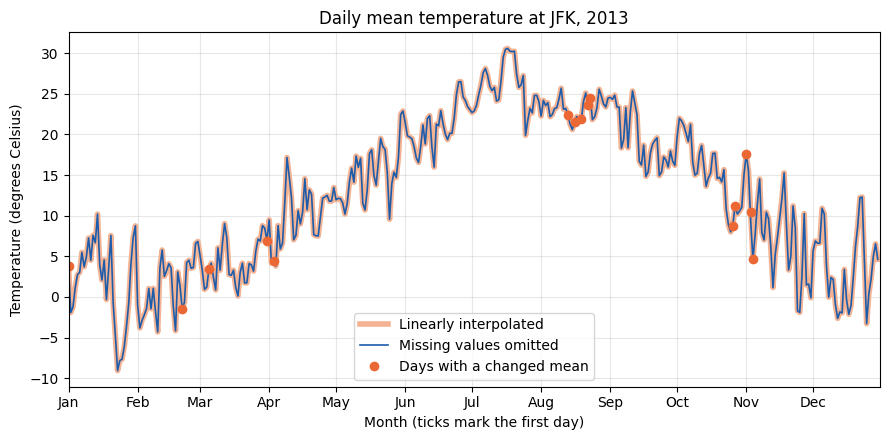

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(daily_temp.index, daily_temp["interpolated"], color="#f4b393",
        linewidth=4, label="Linearly interpolated")
ax.plot(daily_temp.index, daily_temp["omitted"], color="#1c5cab",
        linewidth=1.2, label="Missing values omitted")
ax.plot(changed.index, changed["interpolated"], "o", color="#eb6834",
        markersize=6, label="Days with a changed mean")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(pd.Timestamp("2013-01-01"), pd.Timestamp("2013-12-31"))
ax.set_title("Daily mean temperature at JFK, 2013")
ax.set_xlabel("Month (ticks mark the first day)")
ax.set_ylabel("Temperature (degrees Celsius)")
ax.grid(alpha=0.3)
ax.legend(loc="lower center")
plt.tight_layout()
plt.show()

The two lines overlap almost everywhere; even the change of 1.06 degrees on 3 November is
small beside the seasonal and day-to-day swings. The seasonal cycle is clear: the coldest day was 23 January (-9.1 degrees
Celsius on average) and the warmest was 17 July (30.6 degrees). For the daily means of
this year, leaving out the missing hours is therefore nearly as good as interpolating
them.

## Conclusion

This report examined the hourly weather at the three New York City airports in 2013.
After I converted the data to metric units, the 364 daily means at LGA averaged
4.69 metres per second, and the windiest day was 24 November, at 11.32 metres per
second. Eight of the ten windiest days fell between November and March, and several were
close together. I removed one impossible wind speed of 468.66 metres per second at EWR,
which would otherwise have raised that airport's February mean by about 15 per cent. The
monthly comparison then showed that JFK was always the windiest and EWR always the
calmest, with the same peak in March and low in August. At JFK, 49 hourly temperatures
were missing, all because the records were absent, but filling the gaps changed only one
daily mean by more than 0.2 degrees Celsius.

The main lesson concerns data quality. A faulty reading, a shifted time column and
absent records were all easy to overlook, and each could have led to a wrong result. The
analysis has limits: it covers a single year, so the seasonal patterns may not be
typical, and the mean hides short periods of strong wind within a day. It could be
extended by including other years, studying daily maxima and wind direction, filling
gaps with readings from the other two airports, and linking the weather to flight delays
in the same collection.

## Use of Generative AI

Generative AI was not used to draft the code and the explanatory text of this
homework.

## References

[1] H. Wickham, "nycflights13: Flights that departed NYC in 2013," R package.
Available: https://cran.r-project.org/package=nycflights13

[2] W. McKinney, "Data structures for statistical computing in Python," in
*Proc. 9th Python in Science Conf.*, 2010, pp. 56-61.

[3] C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585,
no. 7825, pp. 357-362, 2020.

[4] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in
Science & Engineering*, vol. 9, no. 3, pp. 90-95, 2007.

[5] J. Courtney *et al.*, "Documentation and verification of the world extreme wind
gust record: 113.3 m/s on Barrow Island, Australia, during passage of tropical cyclone
Olivia," *Australian Meteorological and Oceanographic Journal*, vol. 62, no. 1,
pp. 1-9, 2012.